# Import

In [1]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.width', 200)

# Each file has two sheets: 'Data' and 'Codebook'
df28 = pd.read_excel('SCCS_CGI_recoded_v6.xlsx', sheet_name='Data')
cb28 = pd.read_excel('SCCS_CGI_recoded_v6.xlsx', sheet_name='Codebook')
df70 = pd.read_excel('SCCS_CGI_70_recoded_v1.xlsx', sheet_name='Data')
cb70 = pd.read_excel('SCCS_CGI_70_recoded_v1.xlsx', sheet_name='Codebook')

print(df28.shape, df70.shape)   # expect (28, 89) and (70, 24)

(28, 89) (70, 24)


# Clean data

In [2]:
# Clean up file
df28.columns = df28.columns.str.strip()
cb28['Column'] = cb28['Column'].str.strip()
df28['Communities'] = df28['Communities'].str.strip()
df28 = df28.set_index('Communities')

In [3]:
df28 # 27 Communities, 88 fields 

,Region,Size,Time,AssemblyCentral,AssemblyLocal,CouncilCentral,CouncilLocal,Gathering,TribunalCourt,Scrutiny of officials,Term limits,Turnover,FrequentRegular mtg,Judicial review,Exit,Representation,Delegation,Consultation,Checks and balances,Consent,Agenda setting,Appeal,Majority voting,Supermajority,Plurality voting,Unanimity,Consensus,Voting,Group voting,Vote by proxy,Vote by show of hands,Secret ballot,Election,Quorum,Ratification/acclamation,Veto,Deliberation,Female participation,Child participation,Public meetings,Gerontocracy,Meritocracy,Matriarchy,Matrilineality,Heredity,Blood relations,Patronage for office,Property requirement,Popularity,Election.1,LotteryRandom selection,Screening process,Life appointment,Age boundaries,Payment for office,Remunerated position,Cooptation,Litigation,Arbitration,Mediation,Negotiation,Ostracism,Corporal punishment,Graduated sanctions,Fines,Capital punishment,Oath,Criticism,Reputational risk,MST_ag,MST_hunting,MST_gathering,MST_animal husbandry,MST_fishing,MST_trade,MST_Manufacturing,FoodSupply,InternalMarket,ExternalMarket,CommonProperty,PopDensity,Urbanization,ClassDiff_ordinal,InternalConflict,Warfare,WomenLaborControl,FoodSurplus,MoneyCredit
Communities,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Ajie,Oceania,less than 100,1845,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,1.0,1.0,1.0,1,1,1.0,NaN,NaN,NaN,1,1
Ashanti,Africa,100-1000,1895,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,2,2,0.5,1.0,1.0,1.0,1,1
Chiricahua,North America,less than 100,1870,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,1,1,1.0,1.0,1.0,1.0,1,0
Comanche,North America,100-1000,1870,0,0,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,0,0,0,0,1,0,1,0,2,1,1,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,2.0,1.0,1.0,1.0,1,2,1.0,1.0,1.0,1.0,1,0
Deg Xit'an (Ingalik),North America,less than 100,1885,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,0,0,0,0,0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,2.0,1.0,1.0,0.0,1,1,0.5,1.0,1.0,1.0,1,1
Eastern Pomo (Pomo),North America,100-1000,1850,0,0,1,0,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,1.0,1.0,1.0,1,2,0.5,1.0,0.0,NaN,1,1
Hidatsa,North America,100-1000,1836,0,0,1,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,2,0,0,0,1,2,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1,2,1.0,1.0,1.0,1.0,1,0
Huichol,North America,100-1000,1890,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,NaN,NaN,NaN,1,2,0.5,1.0,NaN,1.0,1,2
Huron (Wendat),North America,1000-5000,1634,0,0,1,3,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,1,1,0,0,0,0,0,0,0,0,1,0,1,0,0,1,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,1.0,1.0,0.0,2,3,0.5,1.0,1.0,1.0,1,0


In [4]:
df70.loc[df70['CGI']==1]

,Community,Region,Size,Time,CGI,MST_ag,MST_hunting,MST_gathering,MST_animal husbandry,MST_fishing,MST_trade,MST_Manufacturing,FoodSupply,InternalMarket,ExternalMarket,PropertyRegime,PopDensity,Urbanization,ClassDiff_ordinal,InternalConflict,Warfare,WomenLaborControl,FoodSurplus,MoneyCredit
42,Ajie,Oceania,less than 100,1845,1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,1.0,1.0,1.0,1.0,1,1.0,NaN,NaN,NaN,1,1.0
43,Ashanti,Africa,100-1000,1895,1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,2.0,2,0.5,1.0,1.0,1.0,1,1.0
44,Chiricahua,North America,less than 100,1870,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,1.0,1,1.0,1.0,1.0,1.0,1,0.0
45,Comanche,North America,100-1000,1870,1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,2.0,1.0,1.0,1.0,1.0,2,1.0,1.0,1.0,1.0,1,0.0
46,Deg Xit'an (Ingalik),North America,less than 100,1885,1,0.0,0.0,0.0,0.0,1.0,0.0,0.0,2.0,1.0,1.0,0.0,1.0,1,0.5,1.0,1.0,1.0,1,1.0
47,Eastern Pomo,North America,100-1000,1850,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,1.0,1.0,1.0,1.0,2,0.5,1.0,0.0,NaN,1,1.0
48,Hidatsa,North America,100-1000,1836,1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,2,1.0,1.0,1.0,1.0,1,0.0
49,Huichol,North America,100-1000,1890,1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,NaN,NaN,NaN,1.0,2,0.5,1.0,NaN,1.0,1,2.0
50,Huron,North America,1000-5000,1634,1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,1.0,1.0,0.0,2.0,3,0.5,1.0,1.0,1.0,1,0.0
51,Kutenai,North America,100-1000,1890,1,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0,2,1.0,1.0,NaN,1.0,1,2.0


In [5]:
df70['CGI'].value_counts()

CGI
0    42
1    28
Name: count, dtype: int64

In [6]:
"""
todo

- df28: 
    - 1. pairwise correlations 
    - 2. clustering

- df70: 
    - 3. compare cgi vs. non-cgi 
        - regional analysis b/n the two 

- significance testing 

"""

'\ntodo\n\n- df28: \n    - 1. pairwise correlations \n    - 2. clustering\n\n- df70: \n    - 3. compare cgi vs. non-cgi \n        - regional analysis b/n the two \n\n- significance testing \n\n'

In [7]:
## df28: CGIs 

In [8]:
# Encode sizes into numerical values
size_order = ['less than 100', '100-1000', '1000-5000', '5000-50000', 'more than 50000']
cgi_df = df28.copy()
cgi_df['Size'] = cgi_df['Size'].map({s: i for i, s in enumerate(size_order)})

In [9]:
# Encode regions into numerical values
cgi_df = pd.get_dummies(cgi_df, columns=['Region'], prefix='Region', dtype=int)

In [10]:
cgi_df

,Size,Time,AssemblyCentral,AssemblyLocal,CouncilCentral,CouncilLocal,Gathering,TribunalCourt,Scrutiny of officials,Term limits,Turnover,FrequentRegular mtg,Judicial review,Exit,Representation,Delegation,Consultation,Checks and balances,Consent,Agenda setting,Appeal,Majority voting,Supermajority,Plurality voting,Unanimity,Consensus,Voting,Group voting,Vote by proxy,Vote by show of hands,Secret ballot,Election,Quorum,Ratification/acclamation,Veto,Deliberation,Female participation,Child participation,Public meetings,Gerontocracy,Meritocracy,Matriarchy,Matrilineality,Heredity,Blood relations,Patronage for office,Property requirement,Popularity,Election.1,LotteryRandom selection,Screening process,Life appointment,Age boundaries,Payment for office,Remunerated position,Cooptation,Litigation,Arbitration,Mediation,Negotiation,Ostracism,Corporal punishment,Graduated sanctions,Fines,Capital punishment,Oath,Criticism,Reputational risk,MST_ag,MST_hunting,MST_gathering,MST_animal husbandry,MST_fishing,MST_trade,MST_Manufacturing,FoodSupply,InternalMarket,ExternalMarket,CommonProperty,PopDensity,Urbanization,ClassDiff_ordinal,InternalConflict,Warfare,WomenLaborControl,FoodSurplus,MoneyCredit,Region_Africa,Region_Asia,Region_North America,Region_Oceania,Region_South America
Communities,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Ajie,0,1845,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,1.0,1.0,1.0,1,1,1.0,NaN,NaN,NaN,1,1,0,0,0,1,0
Ashanti,1,1895,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,2,2,0.5,1.0,1.0,1.0,1,1,1,0,0,0,0
Chiricahua,0,1870,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,1,1,1.0,1.0,1.0,1.0,1,0,0,0,1,0,0
Comanche,1,1870,0,0,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,0,0,0,0,1,0,1,0,2,1,1,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,2.0,1.0,1.0,1.0,1,2,1.0,1.0,1.0,1.0,1,0,0,0,1,0,0
Deg Xit'an (Ingalik),0,1885,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,0,0,0,0,0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,2.0,1.0,1.0,0.0,1,1,0.5,1.0,1.0,1.0,1,1,0,0,1,0,0
Eastern Pomo (Pomo),1,1850,0,0,1,0,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,1.0,1.0,1.0,1,2,0.5,1.0,0.0,NaN,1,1,0,0,1,0,0
Hidatsa,1,1836,0,0,1,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,2,0,0,0,1,2,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1,2,1.0,1.0,1.0,1.0,1,0,0,0,1,0,0
Huichol,1,1890,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,NaN,NaN,NaN,1,2,0.5,1.0,NaN,1.0,1,2,0,0,1,0,0
Huron (Wendat),2,1634,0,0,1,3,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,1,1,0,0,0,0,0,0,0,0,1,0,1,0,0,1,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,1.0,1.0,0.0,2,3,0.5,1.0,1.0,1.0,1,0,0,0,1,0,0


In [11]:
### Pairwise Correlations

In [12]:
cgi_df.nunique()

Size                         3
Time                        17
AssemblyCentral              2
AssemblyLocal                2
CouncilCentral               3
CouncilLocal                 4
Gathering                    3
TribunalCourt                3
Scrutiny of officials        1
Term limits                  1
Turnover                     1
FrequentRegular mtg          3
Judicial review              1
Exit                         1
Representation               4
Delegation                   2
Consultation                 2
Checks and balances          2
Consent                      1
Agenda setting               1
Appeal                       1
Majority voting              1
Supermajority                1
Plurality voting             2
Unanimity                    2
Consensus                    3
Voting                       2
Group voting                 1
Vote by proxy                1
Vote by show of hands        1
Secret ballot                1
Election                     2
Quorum  

In [13]:
n = cgi_df.nunique()
n[n <= 1]                  # just the constant columns
n.sort_values()            # everything, constant columns first

Patronage for office         1
MST_trade                    1
MST_gathering                1
Payment for office           1
Vote by proxy                1
Vote by show of hands        1
Secret ballot                1
Quorum                       1
Reputational risk            1
Supermajority                1
Oath                         1
Matrilineality               1
Property requirement         1
Litigation                   1
Election.1                   1
LotteryRandom selection      1
Screening process            1
Cooptation                   1
Age boundaries               1
Matriarchy                   1
Majority voting              1
Group voting                 1
Agenda setting               1
Scrutiny of officials        1
Term limits                  1
Appeal                       1
Turnover                     1
Judicial review              1
Exit                         1
Remunerated position         1
Consent                      1
MST_Manufacturing            1
Region_N

In [14]:
# Note: A lot of these columns have the same value for all communities, may be worth dropping 

In [15]:
constant_cols = n[n <= 1].index.tolist()
cgi_df = cgi_df.drop(columns=constant_cols) # Drop columns that are the same across all communities 

# Correlations

In [16]:
cgi_df.corr(method='spearman')

,Size,Time,AssemblyCentral,AssemblyLocal,CouncilCentral,CouncilLocal,Gathering,TribunalCourt,FrequentRegular mtg,Representation,Delegation,Consultation,Checks and balances,Plurality voting,Unanimity,Consensus,Voting,Election,Ratification/acclamation,Veto,Deliberation,Female participation,Child participation,Public meetings,Gerontocracy,Meritocracy,Heredity,Blood relations,Popularity,Life appointment,Arbitration,Mediation,Negotiation,Ostracism,Corporal punishment,Graduated sanctions,Fines,Capital punishment,Criticism,MST_ag,MST_hunting,MST_animal husbandry,MST_fishing,FoodSupply,InternalMarket,ExternalMarket,CommonProperty,PopDensity,Urbanization,ClassDiff_ordinal,InternalConflict,Warfare,WomenLaborControl,FoodSurplus,MoneyCredit,Region_Africa,Region_Asia,Region_North America,Region_Oceania,Region_South America
Size,1.000000,-0.237458,0.084732,-0.142464,0.110324,-0.209439,-0.169077,-0.278801,0.079776,-0.251328,-0.282440,0.321981,0.084732,0.367171,0.301079,-0.105385,0.084732,0.357667,0.084732,0.325631,-0.252019,0.025548,-0.209701,-0.375241,-0.207001,0.165179,0.367171,0.122112,0.084732,0.325631,-0.132923,-0.282440,-0.142464,-0.282440,-0.142464,-0.282440,-0.282440,0.367171,-0.282440,0.277228,0.134060,-0.080662,-0.437930,-0.009743,0.116642,-0.174268,-0.197666,-0.033902,1.000000,-0.201238,0.212824,-0.066639,0.077746,0.134676,-0.452162,0.027371,-0.288088,0.073568,0.027371,0.122112
Time,-0.237458,1.000000,0.167439,-0.189597,-0.091850,0.034743,0.114718,0.259728,-0.252592,0.060221,-0.275078,-0.215278,0.167439,-0.298998,-0.254984,-0.188946,0.047840,0.129818,0.047840,-0.043090,0.154704,-0.265045,-0.057084,-0.010251,0.096786,0.014443,-0.298998,-0.293013,-0.107639,-0.155125,0.241139,0.167439,0.155125,0.107639,0.198215,0.107639,0.298998,-0.059800,-0.059800,-0.381411,-0.159487,0.565480,0.174676,-0.074570,0.370054,-0.155203,0.209036,0.107835,-0.237458,0.188369,0.399660,0.074023,-0.018530,-0.228115,0.677986,0.492584,0.308566,-0.253669,-0.278165,-0.198215
AssemblyCentral,0.084732,0.167439,1.000000,-0.053376,-0.274629,0.145344,0.393593,0.391406,-0.066572,0.255085,-0.037037,-0.066667,1.000000,-0.037037,-0.089730,0.205822,-0.037037,-0.100504,-0.037037,-0.053376,0.268030,-0.100504,-0.078567,-0.111111,0.145148,-0.089453,-0.037037,-0.053376,-0.037037,-0.053376,0.720082,-0.037037,-0.053376,-0.037037,0.693889,-0.037037,-0.037037,-0.037037,-0.037037,0.180937,-0.089087,-0.075378,-0.089087,NaN,NaN,NaN,NaN,0.361855,0.084732,-0.166667,NaN,NaN,NaN,0.132453,0.272166,-0.089730,-0.066667,-0.179161,0.412759,-0.053376
AssemblyLocal,-0.142464,-0.189597,-0.053376,1.000000,-0.148418,0.114252,-0.128915,-0.173562,-0.095940,0.194620,-0.053376,-0.096077,-0.053376,-0.053376,0.232767,0.029662,-0.053376,-0.144841,-0.053376,-0.076923,0.229924,0.531085,0.679366,0.480384,-0.028525,-0.128915,-0.053376,-0.076923,-0.053376,-0.076923,-0.076870,-0.053376,-0.076923,-0.053376,-0.076923,-0.053376,-0.053376,-0.053376,0.693889,-0.035644,-0.128698,-0.108893,0.273483,0.318105,-1.000000,0.104828,0.181568,0.073008,-0.142464,-0.240192,0.069007,0.050000,0.125000,0.190885,-0.065372,-0.129315,-0.096077,0.019861,0.232767,-0.076923
CouncilCentral,0.110324,-0.091850,-0.274629,-0.148418,1.000000,-0.073481,-0.343490,0.027906,0.101370,0.332791,0.343286,0.123583,-0.274629,0.068657,0.299407,-0.190770,0.343286,0.279462,0.343286,0.098945,-0.010140,0.000000,0.109233,-0.088273,0.322357,0.261763,0.068657,-0.148418,0.068657,0.098945,-0.395510,-0.274629,-0.148418,0.068657,-0.148418,0.068657,0.068657,0.068657,0.068657,-0.345745,0.450802,0.078242,-0.052016,-0.255819,0.226779,-0.111907,-0.192154,-0.084327,0.110324,0.231718,-0.311922,-0.042696,0.044426,-0.327379,-0.210219,0.133070,-0.082389,0.281024,-0.499011,0.098945
CouncilLocal,-0.209439,0.034743,0.145344,0.114252,-0.073481,1.000000,-0.267154,0.113550,0.486867,0.482923,0.330327,0.182340,0.145344,0.330327,0.224081,0.401754,-0.171770,-0.322695,-0.171770,0.342757,0.223114,0.131468,-0.098102,-0.028314,0.597512,-0.005927,0.330327,-0.019042,-0.171770,-0.019042,-0.01

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

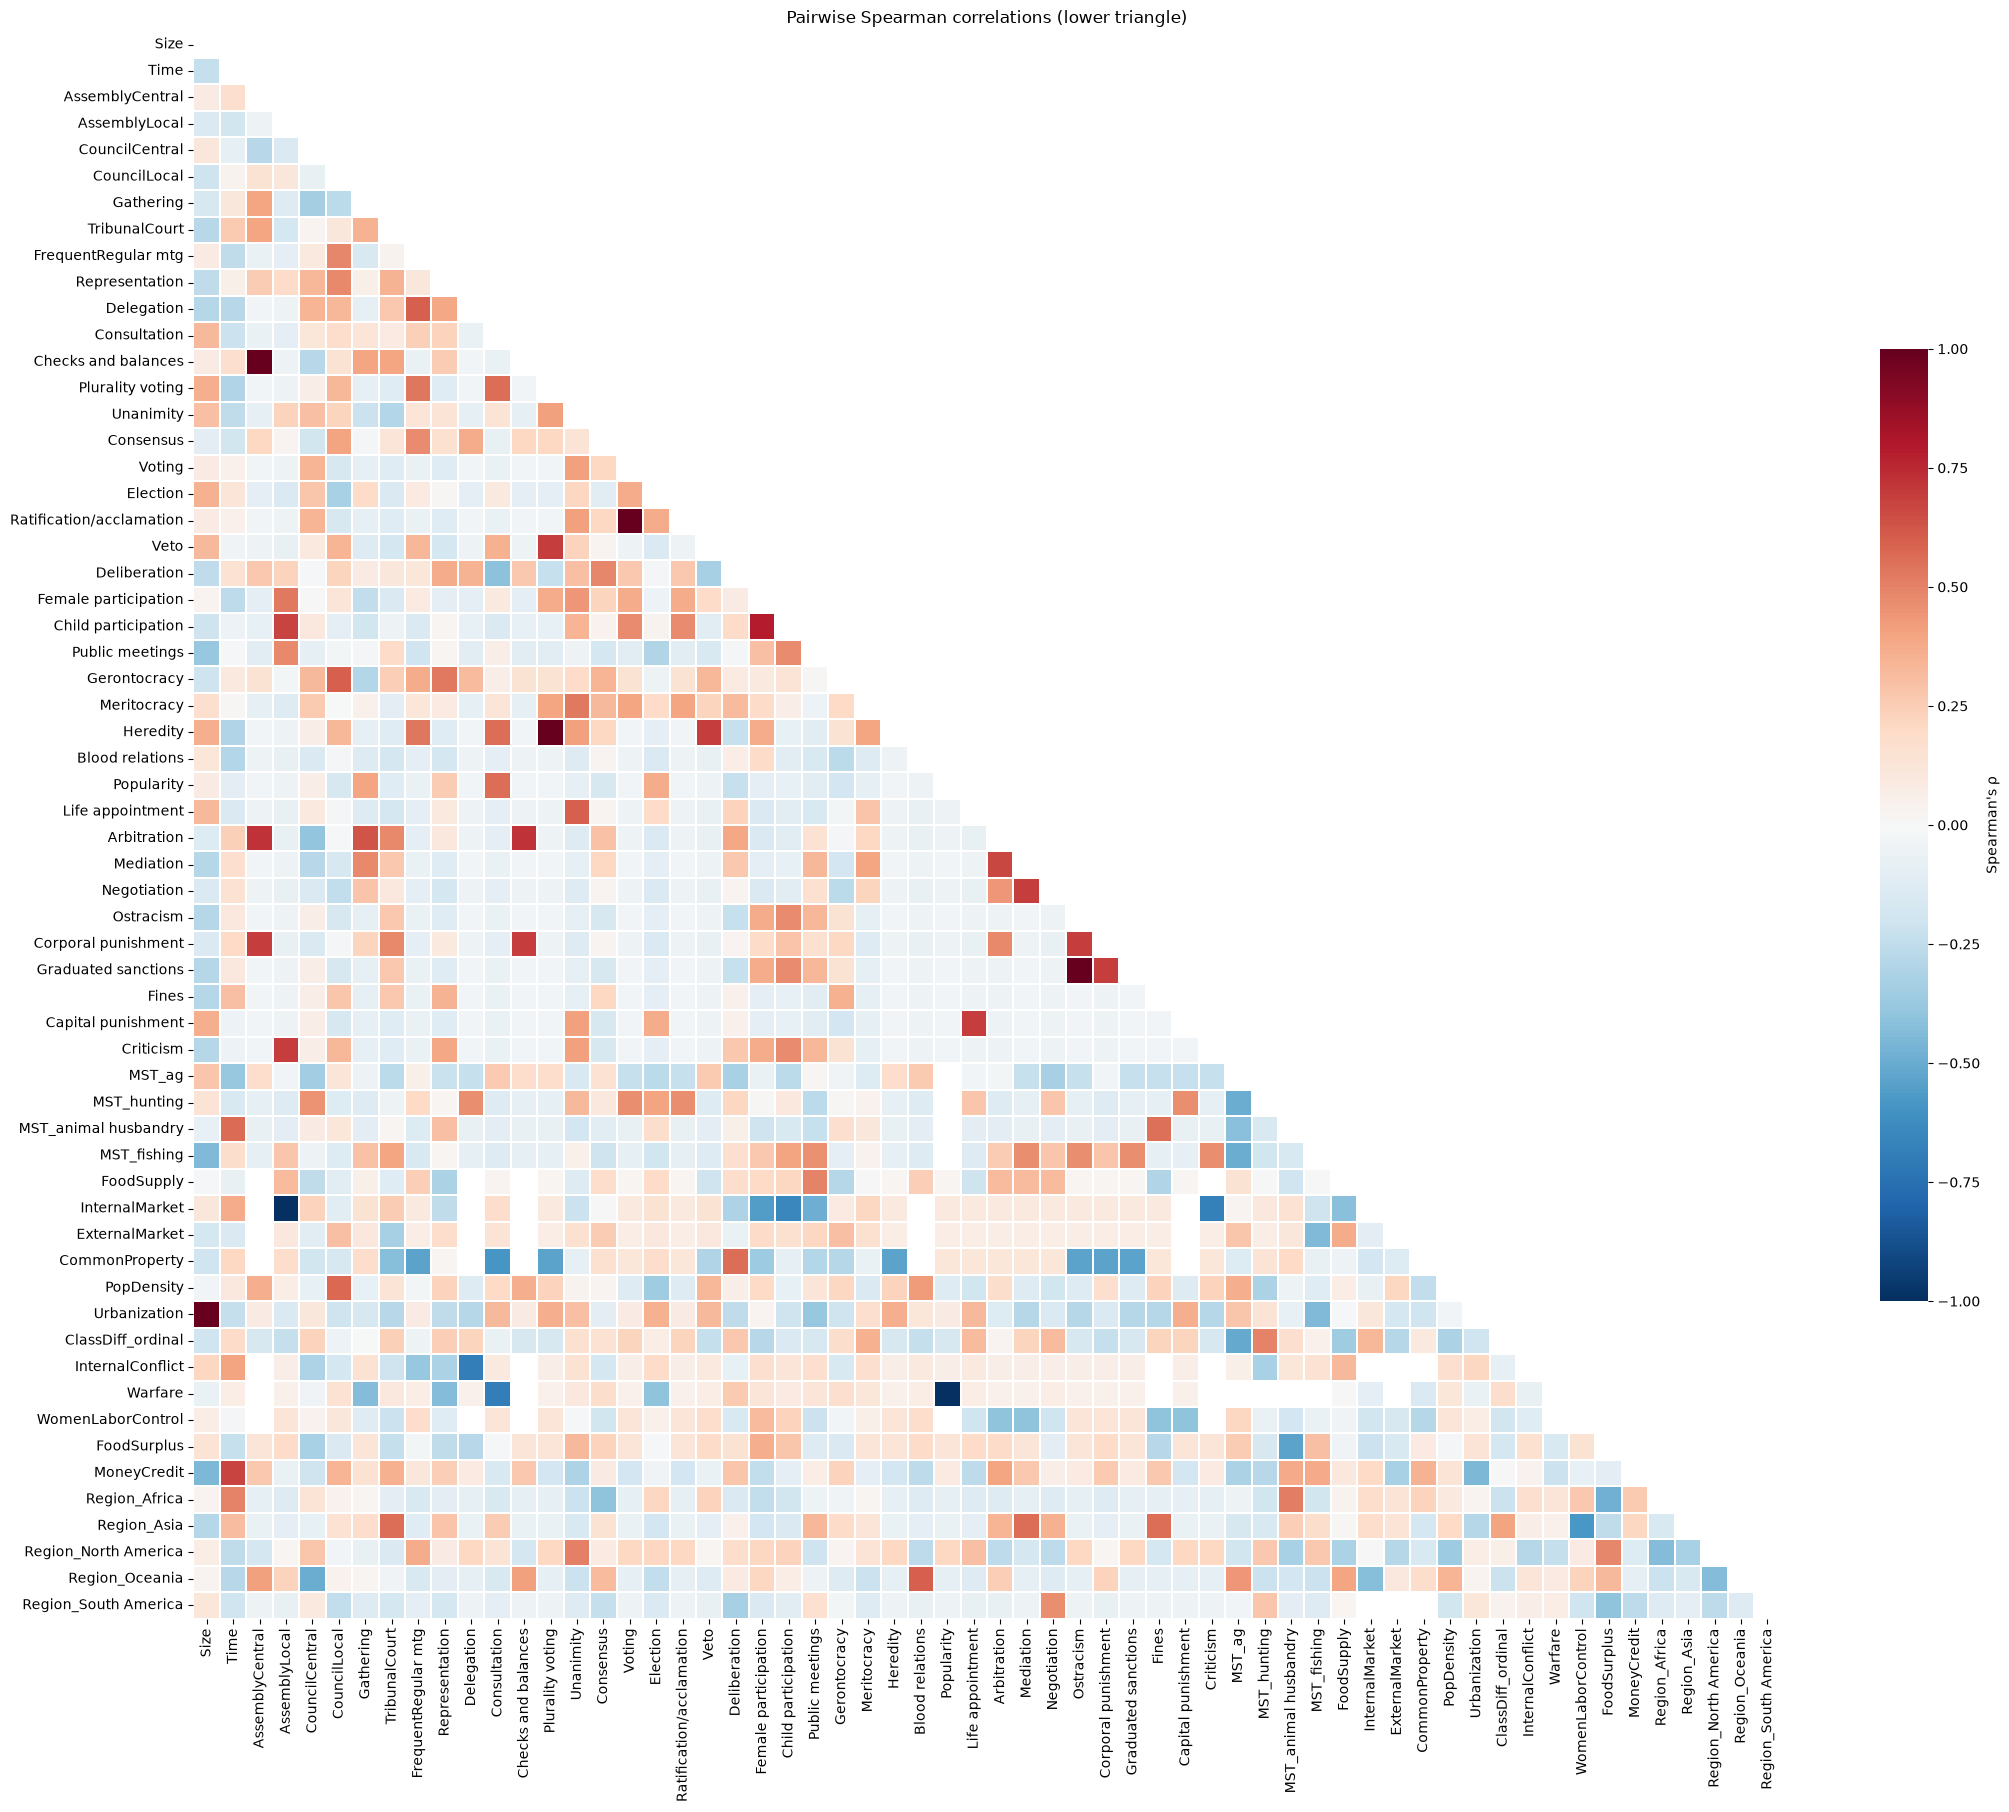

In [18]:
# Heatmap of pairwise correlations
corr = cgi_df.corr(method='spearman')
mask = np.triu(np.ones_like(corr, dtype=bool))   # hide upper triangle and diagonal

fig, ax = plt.subplots(figsize=(22, 18))
ax.set_facecolor('white')
sns.heatmap(corr, mask=mask, cmap='RdBu_r', vmin=-1, vmax=1, center=0,
            square=True, linewidths=0.2, linecolor='white',
            cbar_kws={'label': "Spearman's ρ", 'shrink': 0.6}, ax=ax)
ax.set_title('Pairwise Spearman correlations (lower triangle)')
plt.tight_layout()
plt.show()

In [19]:
### Highest value correlations (positive and negative)
pairs = corr.where(~mask).stack().reset_index()      # lower triangle only, NaNs dropped
pairs.columns = ['var1', 'var2', 'rho']
pairs = pairs.sort_values('rho', key=abs, ascending=False)

pairs.head(20).round(2)

,var1,var2,rho
2643,InternalMarket,AssemblyLocal,-1.00
2880,Urbanization,Size,1.00
3088,Warfare,Popularity,-1.00
722,Checks and balances,AssemblyCentral,1.00
2133,Graduated sanctions,Ostracism,1.00
1096,Ratification/acclamation,Voting,1.00
1573,Heredity,Plurality voting,1.00
1341,Child participation,Female participation,0.78
1812,Arbitration,Checks and balances,0.72
1802,Arbitration,AssemblyCentral,0.72


In [20]:
# TODO: Add p-values + frequency filter

In [21]:
### Split governnace from outcomes

In [22]:
from statsmodels.stats.multitest import multipletests   # pip install statsmodels

gov_cols = cb28.loc[cb28['Type'].isin(['Institution', 'Mechanism']), 'Column'].tolist()
out_cols = cb28.loc[cb28['Type'].str.startswith('Outcome'), 'Column'].tolist()

gov = (df28[gov_cols].fillna(0) > 0).astype(int)   # present (1) / absent (0)
out = df28[out_cols].astype(float).copy()

print(f'{len(gov_cols)} governance columns, {len(out_cols)} outcome columns')

66 governance columns, 19 outcome columns


In [23]:
gov

,AssemblyCentral,AssemblyLocal,CouncilCentral,CouncilLocal,Gathering,TribunalCourt,Scrutiny of officials,Term limits,Turnover,FrequentRegular mtg,Judicial review,Exit,Representation,Delegation,Consultation,Checks and balances,Consent,Agenda setting,Appeal,Majority voting,Supermajority,Plurality voting,Unanimity,Consensus,Voting,Group voting,Vote by proxy,Vote by show of hands,Secret ballot,Election,Quorum,Ratification/acclamation,Veto,Deliberation,Female participation,Child participation,Public meetings,Gerontocracy,Meritocracy,Matriarchy,Matrilineality,Heredity,Blood relations,Patronage for office,Property requirement,Popularity,Election.1,LotteryRandom selection,Screening process,Life appointment,Age boundaries,Payment for office,Remunerated position,Cooptation,Litigation,Arbitration,Mediation,Negotiation,Ostracism,Corporal punishment,Graduated sanctions,Fines,Capital punishment,Oath,Criticism,Reputational risk
Communities,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Ajie,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Ashanti,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Chiricahua,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Comanche,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,0,0,0,0,1,0,1,0,1,1,1,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Deg Xit'an (Ingalik),0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,0,0,0,0,0
Eastern Pomo (Pomo),0,0,1,0,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Hidatsa,0,0,1,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Huichol,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Huron (Wendat),0,0,1,1,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,1,1,0,0,0,0,0,0,0,0,1,0,1,0,0,1,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [24]:
out

,MST_ag,MST_hunting,MST_gathering,MST_animal husbandry,MST_fishing,MST_trade,MST_Manufacturing,FoodSupply,InternalMarket,ExternalMarket,CommonProperty,PopDensity,Urbanization,InternalConflict,Warfare,WomenLaborControl,ClassDiff_ordinal,FoodSurplus,MoneyCredit
Communities,,,,,,,,,,,,,,,,,,,
Ajie,1.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,1.0,1.0,1.0,1.0,1.0,NaN,NaN,NaN,1.0,1.0,1.0
Ashanti,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,2.0,2.0,1.0,1.0,1.0,0.5,1.0,1.0
Chiricahua,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0
Comanche,0.0,1.0,0.0,0.0,0.0,0.0,0.0,2.0,1.0,1.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,1.0,0.0
Deg Xit'an (Ingalik),0.0,0.0,0.0,0.0,1.0,0.0,0.0,2.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,0.5,1.0,1.0
Eastern Pomo (Pomo),NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,1.0,1.0,1.0,1.0,2.0,1.0,0.0,NaN,0.5,1.0,1.0
Hidatsa,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,1.0,0.0
Huichol,1.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,NaN,NaN,NaN,1.0,2.0,1.0,NaN,1.0,0.5,1.0,2.0
Huron (Wendat),1.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,1.0,1.0,0.0,2.0,3.0,1.0,1.0,1.0,0.5,1.0,0.0


In [25]:
### Keep only columns w/ enough variance, for robustness
MIN_N = 5

# Governance: present in >=5 communities AND absent in >=5
n_present = gov.sum()
gov_keep = n_present[(n_present >= MIN_N) & (n_present <= len(gov) - MIN_N)].index.tolist()

# Outcomes: at least 5 communities differ from the most common value (ignoring missing)
def enough_variation(s, min_n=MIN_N):
    s = s.dropna()
    return s.nunique() > 1 and (len(s) - s.value_counts().iloc[0]) >= min_n

out_keep = [c for c in out_cols if enough_variation(out[c])]

print(f'Governance features kept ({len(gov_keep)}):', gov_keep)
print(f'Outcomes kept ({len(out_keep)}):', out_keep)
print('Outcomes dropped:', [c for c in out_cols if c not in out_keep])

Governance features kept (13): ['CouncilCentral', 'CouncilLocal', 'Gathering', 'TribunalCourt', 'Representation', 'Unanimity', 'Consensus', 'Election', 'Deliberation', 'Female participation', 'Public meetings', 'Gerontocracy', 'Meritocracy']
Outcomes kept (8): ['MST_ag', 'FoodSupply', 'PopDensity', 'Urbanization', 'WomenLaborControl', 'ClassDiff_ordinal', 'FoodSurplus', 'MoneyCredit']
Outcomes dropped: ['MST_hunting', 'MST_gathering', 'MST_animal husbandry', 'MST_fishing', 'MST_trade', 'MST_Manufacturing', 'InternalMarket', 'ExternalMarket', 'CommonProperty', 'InternalConflict', 'Warfare']


In [26]:
# Calculate spearman correlations b/n each governance feature x outcomes 
rows = []
for g in gov_keep:
    for o in out_keep:
        pair = pd.concat([gov[g], out[o]], axis=1).dropna()   # only communities with outcome data
        rho, p = stats.spearmanr(pair[g], pair[o])
        rows.append({'feature': g, 'outcome': o, 'N': len(pair),
                     'n_with_feature': int(pair[g].sum()), 'rho': rho, 'p': p})

res = pd.DataFrame(rows)
# Benjamini-Hochberg correction - adjusted p-values to control for False Disovery Rate
# https://www.statsmodels.org/devel/generated/statsmodels.stats.multitest.multipletests.html
res['q'] = multipletests(res['p'], method='fdr_bh')[1]

res

,feature,outcome,N,n_with_feature,rho,p,q
0,CouncilCentral,MST_ag,25,18,-0.193829,0.353214,0.800626
1,CouncilCentral,FoodSupply,22,16,-0.323815,0.141530,0.745530
2,CouncilCentral,PopDensity,28,20,0.023784,0.904381,0.931243
3,CouncilCentral,Urbanization,28,20,0.174036,0.375773,0.800626
4,CouncilCentral,WomenLaborControl,21,16,-0.050000,0.829586,0.931243
5,CouncilCentral,ClassDiff_ordinal,28,20,0.068465,0.729212,0.894174
6,CouncilCentral,FoodSurplus,28,20,-0.266008,0.171247,0.745530
7,CouncilCentral,MoneyCredit,28,20,-0.260875,0.179973,0.745530
8,CouncilLocal,MST_ag,25,13,0.277425,0.179388,0.745530
9,CouncilLocal,FoodSupply,22,8,-0.089128,0.693262,0.891660


In [27]:
print(f"{len(res)} tests | p < .05: {(res.p < .05).sum()} | "
      f"expected by chance: {0.05 * len(res):.1f} | q < .10: {(res.q < .10).sum()}")
res.sort_values('p').head(15).round(3)

104 tests | p < .05: 3 | expected by chance: 5.2 | q < .10: 1


,feature,outcome,N,n_with_feature,rho,p,q
10,CouncilLocal,PopDensity,28,13,0.592,0.001,0.093
81,Public meetings,FoodSupply,22,5,0.493,0.020,0.746
83,Public meetings,Urbanization,28,7,-0.375,0.049,0.746
31,TribunalCourt,MoneyCredit,28,8,0.373,0.051,0.746
15,CouncilLocal,MoneyCredit,28,13,0.371,0.052,0.746
78,Female participation,FoodSurplus,28,6,0.359,0.060,0.746
59,Election,Urbanization,28,6,0.358,0.062,0.746
58,Election,PopDensity,28,6,-0.353,0.065,0.746
101,Meritocracy,ClassDiff_ordinal,28,5,0.350,0.068,0.746
24,TribunalCourt,MST_ag,25,7,-0.345,0.092,0.746


In [28]:
# Show significant results before correction
sig = res[res['p'] < .05].sort_values('p').round(3)
print(f"{len(sig)} of {len(res)} tests at p < .05 (≈{0.05 * len(res):.1f} expected by chance)")
sig

3 of 104 tests at p < .05 (≈5.2 expected by chance)


,feature,outcome,N,n_with_feature,rho,p,q
10,CouncilLocal,PopDensity,28,13,0.592,0.001,0.093
81,Public meetings,FoodSupply,22,5,0.493,0.020,0.746
83,Public meetings,Urbanization,28,7,-0.375,0.049,0.746


- local councils x higher population density 
- public meetings x more hunger 
- public meetings x less urbanization 

In [29]:
# Show significant results after correction
res[res['q'] < .10].sort_values('q').round(3)

,feature,outcome,N,n_with_feature,rho,p,q
10,CouncilLocal,PopDensity,28,13,0.592,0.001,0.093


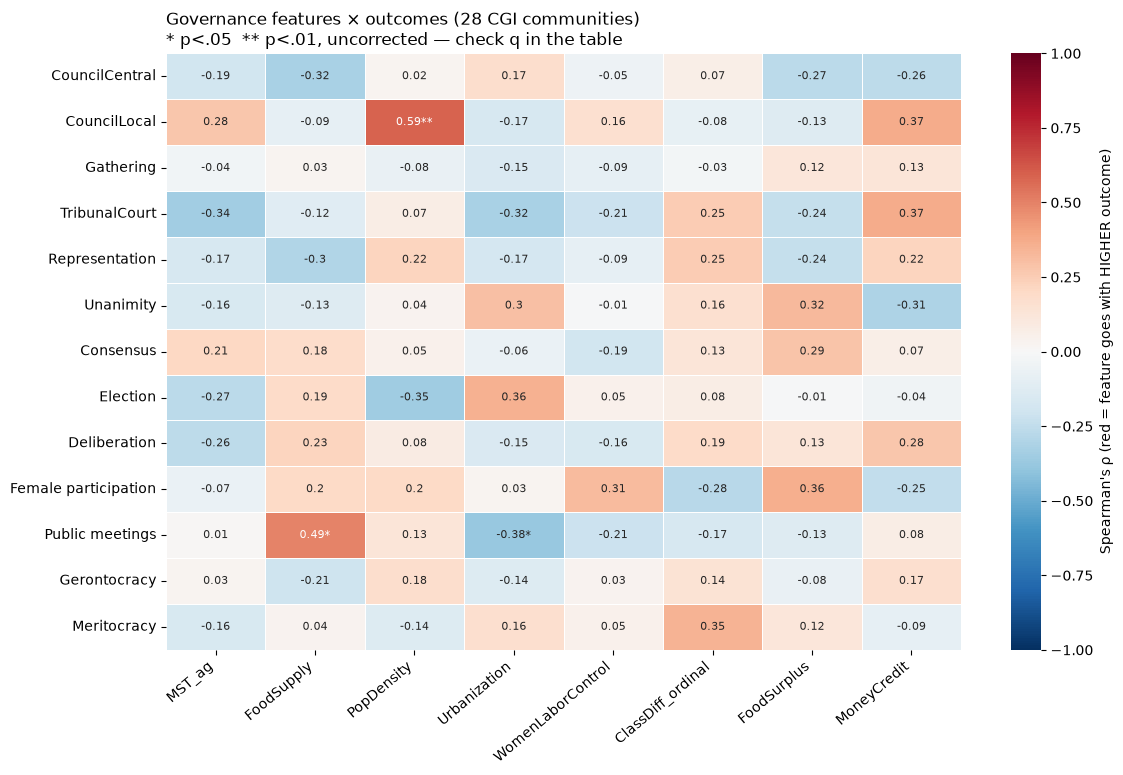

In [30]:
### Heatmap
rho_mat = res.pivot(index='feature', columns='outcome', values='rho').loc[gov_keep, out_keep]
p_mat   = res.pivot(index='feature', columns='outcome', values='p').loc[gov_keep, out_keep]

def star(p):
    return '**' if p < .01 else '*' if p < .05 else ''

labels = rho_mat.round(2).astype(str) + p_mat.map(star)

fig, ax = plt.subplots(figsize=(1.1 * len(out_keep) + 3, 0.45 * len(gov_keep) + 2))
sns.heatmap(rho_mat, annot=labels, fmt='', cmap='RdBu_r', vmin=-1, vmax=1, center=0,
            linewidths=0.5, linecolor='white', annot_kws={'fontsize': 8},
            cbar_kws={'label': "Spearman's ρ (red = feature goes with HIGHER outcome)"}, ax=ax)
ax.set_xlabel(''); ax.set_ylabel('')
ax.set_title('Governance features × outcomes (28 CGI communities)\n'
             '* p<.05  ** p<.01, uncorrected — check q in the table', loc='left')
plt.xticks(rotation=40, ha='right'); plt.tight_layout(); plt.show()

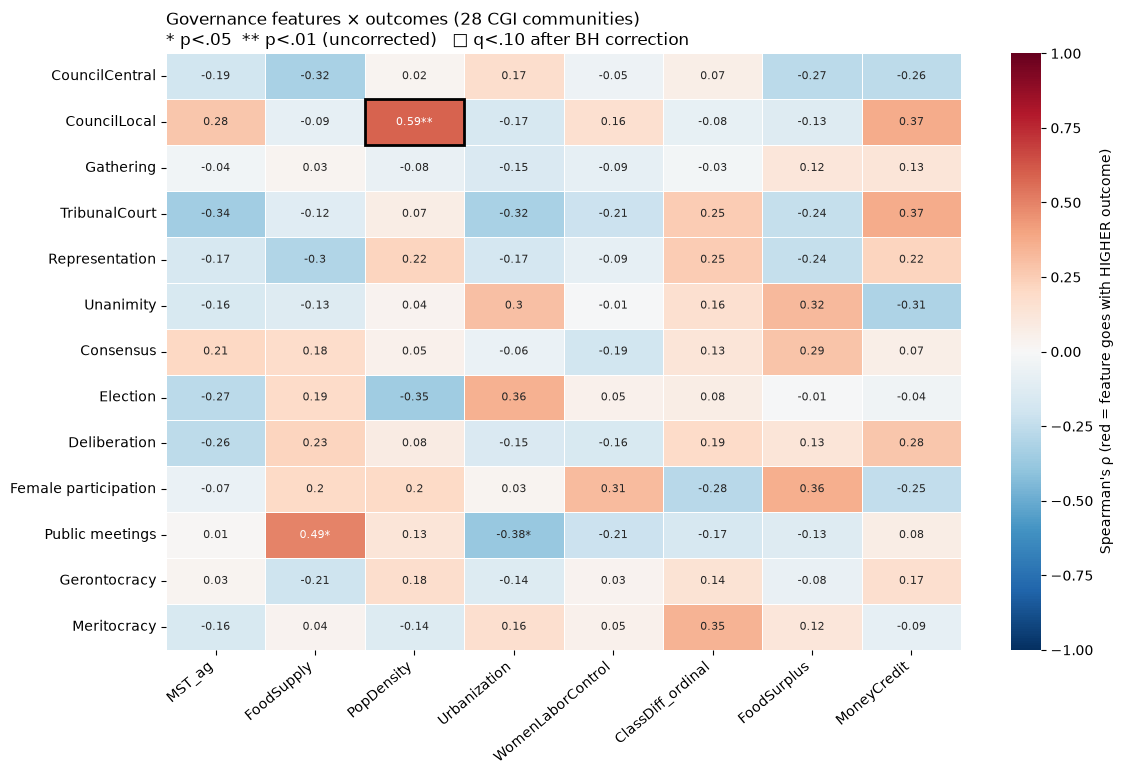

In [31]:
from matplotlib.patches import Rectangle

q_mat = res.pivot(index='feature', columns='outcome', values='q').loc[gov_keep, out_keep]
labels = rho_mat.round(2).astype(str) + p_mat.map(star)

fig, ax = plt.subplots(figsize=(1.1 * len(out_keep) + 3, 0.45 * len(gov_keep) + 2))
sns.heatmap(rho_mat, annot=labels, fmt='', cmap='RdBu_r', vmin=-1, vmax=1, center=0,
            linewidths=0.5, linecolor='white', annot_kws={'fontsize': 8},
            cbar_kws={'label': "Spearman's ρ (red = feature goes with HIGHER outcome)"}, ax=ax)

# Box the cells that survive correction
for i, f in enumerate(gov_keep):
    for j, o in enumerate(out_keep):
        if q_mat.loc[f, o] < .10:
            ax.add_patch(Rectangle((j, i), 1, 1, fill=False, edgecolor='black', lw=2))

ax.set_xlabel(''); ax.set_ylabel('')
ax.set_title('Governance features × outcomes (28 CGI communities)\n'
             '* p<.05  ** p<.01 (uncorrected)   □ q<.10 after BH correction', loc='left')
plt.xticks(rotation=40, ha='right'); plt.tight_layout(); plt.show()

In [32]:
# Change these two names to any pair from the table
f, o = 'CouncilLocal', 'PopDensity'
pd.crosstab(gov[f], out[o], margins=True).rename_axis(index=f'{f} (1=present)', columns=o)

PopDensity,1.0,2.0,3.0,All
CouncilLocal (1=present),,,,
0,14,1,0,15
1,5,5,3,13
All,19,6,3,28


In [33]:
# Percentages within each row instead of counts
pd.crosstab(gov[f], out[o], normalize='index').round(2)

PopDensity,1.0,2.0,3.0
CouncilLocal,,,
0,0.93,0.07,0.00
1,0.38,0.38,0.23


In [34]:
# See which communities are in each cell
pd.concat([gov[f], out[o]], axis=1).sort_values([f, o])

,CouncilLocal,PopDensity
Communities,,
Chiricahua,0,1.0
Comanche,0,1.0
Deg Xit'an (Ingalik),0,1.0
Eastern Pomo (Pomo),0,1.0
Kutenai,0,1.0
Maasi (Masai),0,1.0
Maori,0,1.0
Nama,0,1.0
Natchez people,0,1.0


In [35]:
# Descriptive "all / none" patterns: feature present in >= 5 communities
rows = []
for f in [c for c in gov.columns if gov[c].sum() >= 5]:
    for o in out.columns:
        d = pd.concat([gov[f], out[o]], axis=1).dropna()
        w, wo = d.loc[d[f] == 1, o], d.loc[d[f] == 0, o]
        if len(w) < 5 or len(wo) < 4:
            continue
        for v in sorted(d[o].unique()):
            share_w, share_wo = (w == v).mean(), (wo == v).mean()
            if share_w == 1 and share_wo < .75:
                rows.append((f, o, v, 'ALL with feature', f'{(w==v).sum()}/{len(w)}', f'{(wo==v).sum()}/{len(wo)}'))
            elif share_w == 0 and share_wo >= .25:
                rows.append((f, o, v, 'NONE with feature', f'0/{len(w)}', f'{(wo==v).sum()}/{len(wo)}'))

patterns = pd.DataFrame(rows, columns=['feature', 'outcome', 'value', 'pattern', 'with feature', 'without feature'])
patterns

,feature,outcome,value,pattern,with feature,without feature
0,Gathering,PopDensity,2.0,NONE with feature,0/5,6/23
1,Unanimity,FoodSurplus,0.0,NONE with feature,0/5,9/23
2,Unanimity,FoodSurplus,1.0,ALL with feature,5/5,14/23
3,Unanimity,MoneyCredit,2.0,NONE with feature,0/5,7/23
4,Election,FoodSupply,1.0,NONE with feature,0/6,6/16
5,Election,PopDensity,1.0,ALL with feature,6/6,13/22
6,Election,PopDensity,2.0,NONE with feature,0/6,6/22
7,Election,Urbanization,1.0,NONE with feature,0/6,8/22
8,Deliberation,CommonProperty,0.0,NONE with feature,0/10,3/6
9,Deliberation,CommonProperty,1.0,ALL with feature,10/10,3/6


In [36]:
### Pairwise correlations of governance features x governance features

# Governance feature × governance feature correlations (13 features → 78 pairs)
from statsmodels.stats.multitest import multipletests

G = gov[gov_keep]
rows = []
for i, a in enumerate(gov_keep):
    for b in gov_keep[i + 1:]:
        table = pd.crosstab(G[a], G[b]).reindex(index=[0, 1], columns=[0, 1], fill_value=0)
        rows.append({'feature_a': a, 'feature_b': b,
                     'n_a': int(G[a].sum()), 'n_b': int(G[b].sum()),
                     'both': int(table.loc[1, 1]),                 # communities with both features
                     'rho': stats.spearmanr(G[a], G[b])[0],
                     'p': stats.fisher_exact(table.values)[1]})

gg = pd.DataFrame(rows)
gg['q'] = multipletests(gg['p'], method='fdr_bh')[1]

print(f"{len(gg)} pairs | p < .05: {(gg.p < .05).sum()} | "
      f"expected by chance: {0.05 * len(gg):.1f} | q < .10: {(gg.q < .10).sum()}")

# Top 15 by strength (positive or negative)
gg.sort_values('rho', key=abs, ascending=False).head(15).round(3)

78 pairs | p < .05: 4 | expected by chance: 3.9 | q < .10: 0


,feature_a,feature_b,n_a,n_b,both,rho,p,q
56,Unanimity,Meritocracy,5,5,3,0.513,0.027,0.787
21,CouncilLocal,Gerontocracy,13,14,10,0.501,0.021,0.787
48,Representation,Gerontocracy,8,14,7,0.474,0.033,0.787
53,Unanimity,Female participation,5,6,3,0.438,0.050,0.787
5,CouncilCentral,Consensus,20,12,6,-0.411,0.044,0.787
14,CouncilLocal,Representation,13,8,6,0.362,0.096,0.938
16,CouncilLocal,Consensus,13,12,8,0.351,0.125,0.938
62,Consensus,Meritocracy,12,5,4,0.350,0.133,0.938
58,Consensus,Deliberation,12,18,10,0.344,0.114,0.938
23,Gathering,TribunalCourt,5,8,3,0.324,0.123,0.938


In [37]:
# Significant pairs only (p < .05, uncorrected; exploratory)
sig_gg = gg[gg['p'] < .05].sort_values('p').round(3)
print(f"{len(sig_gg)} of {len(gg)} pairs at p < .05 (≈{0.05 * len(gg):.1f} expected by chance)")
sig_gg

4 of 78 pairs at p < .05 (≈3.9 expected by chance)


,feature_a,feature_b,n_a,n_b,both,rho,p,q
21,CouncilLocal,Gerontocracy,13,14,10,0.501,0.021,0.787
56,Unanimity,Meritocracy,5,5,3,0.513,0.027,0.787
48,Representation,Gerontocracy,8,14,7,0.474,0.033,0.787
5,CouncilCentral,Consensus,20,12,6,-0.411,0.044,0.787


- No pairs survive BH correction (q < 0.10) 

# Clustering

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import pdist, squareform
from sklearn.metrics import silhouette_score
from sklearn.manifold import MDS

GOV = cb28.loc[cb28['Type'].isin(['Institution', 'Mechanism']), 'Column'].tolist()
X = (df28[GOV].fillna(0) > 0).astype(int)
X = X.loc[:, X.sum() >= 2]          # drop features found in only 0–1 communities
print(X.shape)                      # (communities, features)

(28, 23)


In [39]:
D = pdist(X, metric='jaccard')
Z = linkage(D, method='average')

# Try 2, 3, 4, 5, and 6 clusters
for k in range(2, 7):
    labels = fcluster(Z, k, criterion='maxclust')
    print(k, round(silhouette_score(squareform(D), labels, metric='precomputed'), 3))

2 0.135
3 0.106
4 0.107
5 0.121
6 0.133


In [40]:
def best_silhouette(X):
    D = pdist(X, metric='jaccard')
    Z = linkage(D, method='average')
    Dsq = squareform(D)
    return max(silhouette_score(Dsq, fcluster(Z, k, criterion='maxclust'), metric='precomputed')
               for k in range(2, 7))

rng = np.random.default_rng(0)
observed = best_silhouette(X)
null = [best_silhouette(X.apply(lambda col: rng.permutation(col.values))) for _ in range(200)]

print('observed best silhouette:', round(observed, 3))
print('random data, 5th / 50th / 95th percentile:', np.percentile(null, [5, 50, 95]).round(3))
print('share of random datasets scoring at least as high:', np.mean(np.array(null) >= observed))

observed best silhouette: 0.135
random data, 5th / 50th / 95th percentile: [0.112 0.149 0.211]
share of random datasets scoring at least as high: 0.72


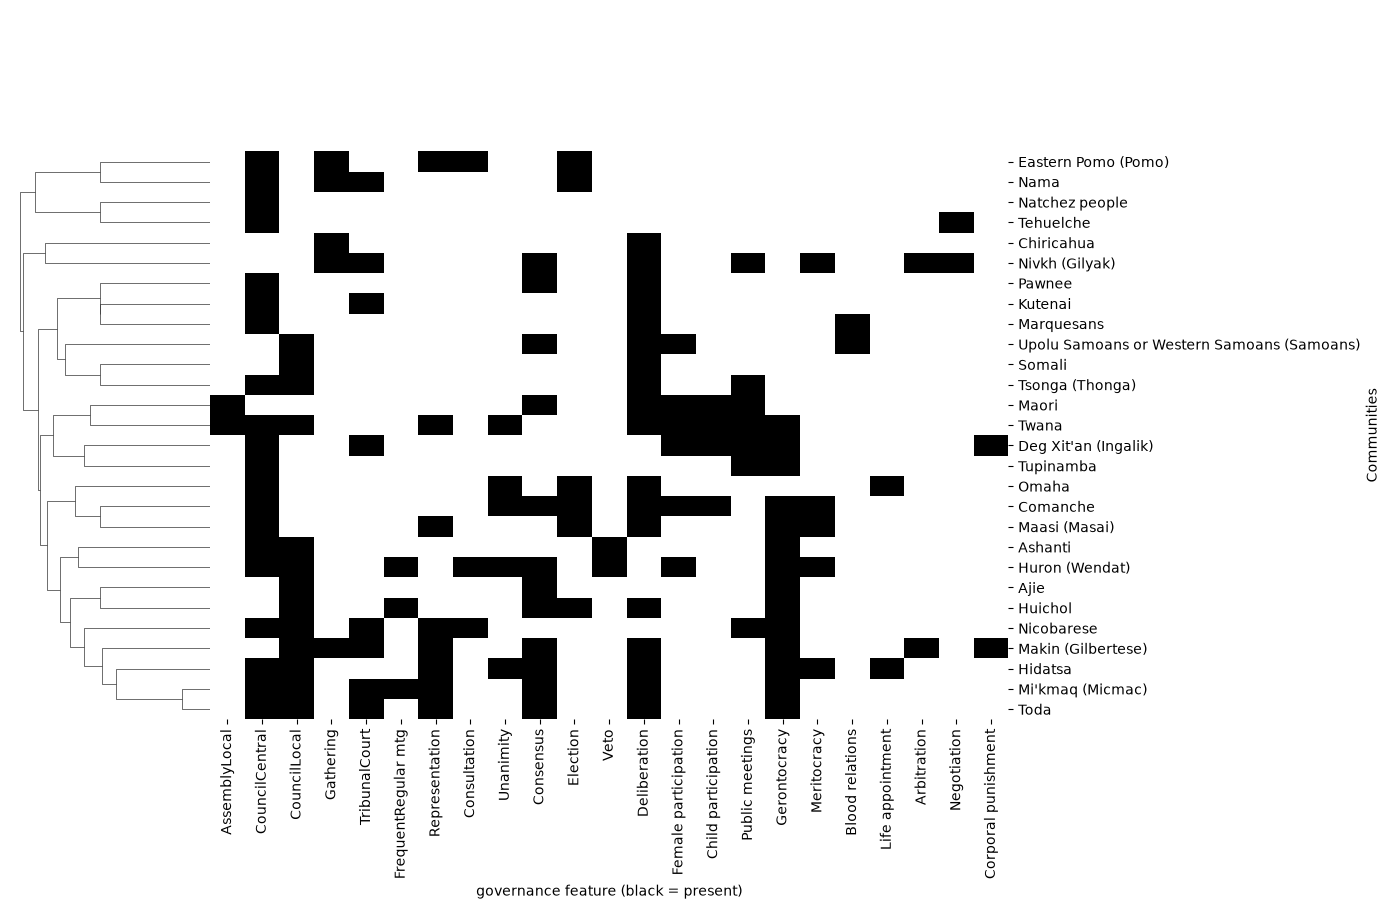

In [41]:
g = sns.clustermap(X.astype(int), row_linkage=Z, col_cluster=False,
                   cmap='Greys', figsize=(14, 9), cbar_pos=None,
                   xticklabels=True, yticklabels=True)
g.ax_heatmap.set_xlabel('governance feature (black = present)')
plt.show()

In [42]:
K = 3   # set after looking at Cells 2 and 3
clusters = pd.Series(fcluster(Z, K, criterion='maxclust'), index=X.index, name='cluster')
clusters.value_counts().sort_index()

cluster
1     4
2     2
3    22
Name: count, dtype: int64

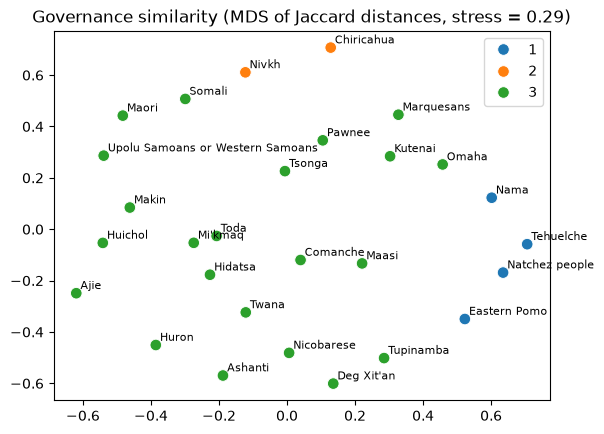

In [43]:
xy = MDS(n_components=2, metric='precomputed', n_init=1, init='classical_mds',
         random_state=0).fit_transform(squareform(D))
stress = np.sqrt(((D - pdist(xy))**2).sum() / (D**2).sum())

ax = sns.scatterplot(x=xy[:, 0], y=xy[:, 1], hue=clusters.values, palette='tab10', s=70)
for name, (x, y) in zip(X.index, xy):
    ax.annotate(name.split('(')[0].strip(), (x, y), fontsize=8, xytext=(3, 3), textcoords='offset points')
ax.set_title(f'Governance similarity (MDS of Jaccard distances, stress = {stress:.2f})')
plt.show()

In [44]:
### Test if clusters are any better than random 

In [45]:
def cluster_score(data, k):
    """Cluster into k groups; return (silhouette score, cluster labels)."""
    D = pdist(data.values.astype(bool), metric='jaccard')   # how different each pair of communities is
    labels = fcluster(linkage(D, method='average'), k, criterion='maxclust')
    return silhouette_score(squareform(D), labels, metric='precomputed'), labels

for k in range(2, 7):
    score, labels = cluster_score(X, k)
    print(f'k={k}: silhouette = {score:.3f}   cluster sizes = {sorted(np.bincount(labels)[1:].tolist(), reverse=True)}')

k=2: silhouette = 0.135   cluster sizes = [24, 4]
k=3: silhouette = 0.106   cluster sizes = [22, 4, 2]
k=4: silhouette = 0.107   cluster sizes = [22, 2, 2, 2]
k=5: silhouette = 0.121   cluster sizes = [16, 6, 2, 2, 2]
k=6: silhouette = 0.133   cluster sizes = [12, 6, 4, 2, 2, 2]


In [46]:
### Compare clusters' silhouette scores to random 
rng = np.random.default_rng(0)

def shuffle(data):
    """Shuffle each feature's column separately: same frequencies, no real co-occurrence."""
    return data.apply(lambda col: rng.permutation(col.values))

X_random = shuffle(X)
print('Each feature still appears in the same number of communities:',
      (X_random.sum() == X.sum()).all())

for k in range(2, 7):
    print(f'k={k}: real = {cluster_score(X, k)[0]:.3f}   shuffled = {cluster_score(X_random, k)[0]:.3f}')

Each feature still appears in the same number of communities: True
k=2: real = 0.135   shuffled = 0.121
k=3: real = 0.106   shuffled = 0.106
k=4: real = 0.107   shuffled = 0.116
k=5: real = 0.121   shuffled = 0.122
k=6: real = 0.133   shuffled = 0.101


In [47]:
def best_score(data):
    return max(cluster_score(data, k)[0] for k in range(2, 7))   # best k, chosen the same way each time

real = best_score(X)
random_scores = np.array([best_score(shuffle(X)) for _ in range(200)])

p = (np.sum(random_scores >= real) + 1) / (len(random_scores) + 1)
print(f'Real data, best silhouette:        {real:.3f}')
print(f'Random data, median:               {np.median(random_scores):.3f}')
print(f'Random data, 95th percentile:      {np.percentile(random_scores, 95):.3f}')
print(f'Share of random runs >= real (p):  {p:.2f}')

Real data, best silhouette:        0.135
Random data, median:               0.149
Random data, 95th percentile:      0.211
Share of random runs >= real (p):  0.73


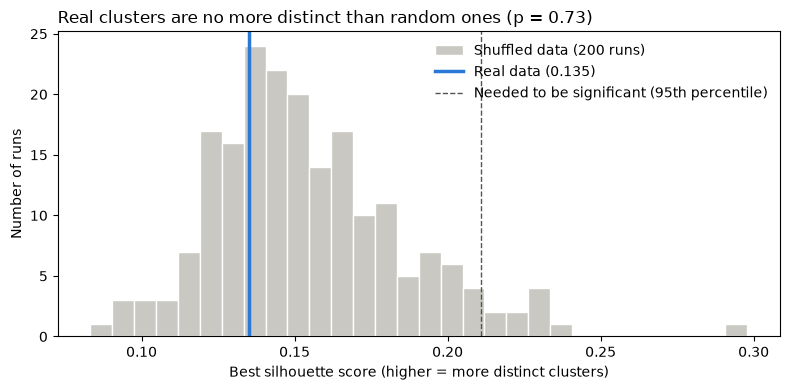

In [48]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(random_scores, bins=30, color='#c9c8c2', edgecolor='white', label='Shuffled data (200 runs)')
ax.axvline(real, color='#2a78d6', lw=2.5, label=f'Real data ({real:.3f})')
ax.axvline(np.percentile(random_scores, 95), color='#55544f', ls='--', lw=1,
           label='Needed to be significant (95th percentile)')
ax.set_xlabel('Best silhouette score (higher = more distinct clusters)')
ax.set_ylabel('Number of runs')
ax.set_title(f'Real clusters are no more distinct than random ones (p = {p:.2f})', loc='left')
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

- Jaccard distance 
- Clusters -- silhouette score of 0.135 is quite low, no substantial structure
- Trying different values for k still results in quite low silhouette scores
- Comparing these clusters to randomly shuffled data - random is even higher
- -> *In this dataset, we find that* communities do not form distinct clusters by governance features. 
- -> May imply: governance design as modular / context-dependent 

# CGI vs. non-CGI

- How do CGI communities differ from non-CGI?
- Do CGI communities have different omtcomes than non-CGI communities?

In [49]:
df70 = pd.read_excel('SCCS_CGI_70_recoded_v1.xlsx', sheet_name='Data')
df70['Community'] = df70['Community'].str.strip()
print(df70['CGI'].value_counts())
pd.crosstab(df70['Region'], df70['CGI'])

CGI
0    42
1    28
Name: count, dtype: int64


CGI,0,1
Region,,
Africa,10,5
Asia,9,3
Europe,1,0
North America,11,13
Oceania,3,5
South America,8,2


In [50]:
print(df70['CGI'].value_counts())

CGI
0    42
1    28
Name: count, dtype: int64
